# MOT Designer

Python companion to the AMO Toolkit page [MOT Designer](https://amotoolkit.com/pages/mot-designer.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/mot-designer.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Constants and species data
The same rounded constants and species table the page uses, so the numbers agree digit for digit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

kB, hbar, muB, amu = 1.380649e-23, 1.054572e-34, 9.274010e-24, 1.660539e-27
ATOMS = {
    "Rb87":  dict(mass_u=86.909,  Gamma_MHz=6.065,  lambda_nm=780.241, muEff_muB=1.0),
    "Cs133": dict(mass_u=132.905, Gamma_MHz=5.234,  lambda_nm=852.347, muEff_muB=1.0),
    "Na23":  dict(mass_u=22.990,  Gamma_MHz=9.795,  lambda_nm=588.996, muEff_muB=1.0),
    "Li7":   dict(mass_u=7.016,   Gamma_MHz=5.8724, lambda_nm=670.977, muEff_muB=1.0),
    "K39":   dict(mass_u=38.964,  Gamma_MHz=6.035,  lambda_nm=766.701, muEff_muB=1.0),
}

## 2. The MOT model
One-dimensional Doppler theory with counter-propagating beams of total saturation *s*:

* damping $\alpha = 8\hbar k^2 s\,|\Delta/\Gamma| / (1+s+4\Delta^2/\Gamma^2)^2$
* spring constant $\kappa = \alpha\,\mu_\mathrm{eff} B'/(\hbar k)$, trap frequency $\sqrt{\kappa/m}$
* capture velocity $v_c \approx |\Delta|/k$
* temperature $k_B T = \frac{\hbar\Gamma}{4}\,\frac{1+s+4\Delta^2/\Gamma^2}{2|\Delta|/\Gamma}$, Doppler limit $\hbar\Gamma/2k_B$
* scattering rate $R = \frac{\Gamma}{2}\frac{s}{1+s+4\Delta^2/\Gamma^2}$, cloud size $\sigma = \sqrt{k_BT/\kappa}$

In [2]:
def mot(species="Rb87", det_gamma=1.5, s=1.0, grad_G_cm=15.0):
    a = ATOMS[species]
    m = a["mass_u"] * amu
    G = 2 * np.pi * a["Gamma_MHz"] * 1e6
    k = 2 * np.pi / (a["lambda_nm"] * 1e-9)
    Delta = -det_gamma * G
    dBdz = grad_G_cm * 0.01                      # G/cm -> T/m
    denom = 1 + s + (2 * Delta / G) ** 2
    alpha = 8 * hbar * k**2 * s * abs(Delta / G) / denom**2
    kappa = alpha * a["muEff_muB"] * muB * dBdz / (hbar * k)
    T_MOT = hbar * G / (8 * kB) * denom / abs(Delta / G)
    return dict(
        alpha=alpha, kappa=kappa,
        f_trap_Hz=np.sqrt(kappa / m) / (2 * np.pi),
        v_cap=abs(Delta) / k,
        T_Doppler_uK=hbar * G / (2 * kB) * 1e6,
        T_MOT_uK=T_MOT * 1e6,
        a_max=hbar * k * G * s / (2 * m * (1 + s)),
        R_sc_MHz=G / 2 * s / denom / 1e6,
        tau_damp_ms=m / alpha * 1e3,
        sigma_um=np.sqrt(kB * T_MOT / kappa) * 1e6,
    )

r = mot()                                         # the page's defaults
for key, v in r.items():
    print(f"{key:>14} = {v:.4g}")

         alpha = 6.782e-22
         kappa = 1.111e-18
     f_trap_Hz = 441.6
         v_cap = 7.098
  T_Doppler_uK = 145.5
      T_MOT_uK = 266.8
         a_max = 5.606e+04
      R_sc_MHz = 1.732
   tau_damp_ms = 0.2128
      sigma_um = 57.58

## 3. Scan the detuning
The page's second chart: damping (normalised to its maximum) and temperature (relative to its minimum) against |Δ|/Γ. Damping peaks near |Δ| = (Γ/2)√((1+s)/3) while the temperature is lowest near |Δ| = (Γ/2)√(1+s): you cannot have both.

s = 0.1: damping peaks at |Δ|/Γ = 0.30, temperature lowest at |Δ|/Γ = 0.53
s = 1.0: damping peaks at |Δ|/Γ = 0.41, temperature lowest at |Δ|/Γ = 0.71

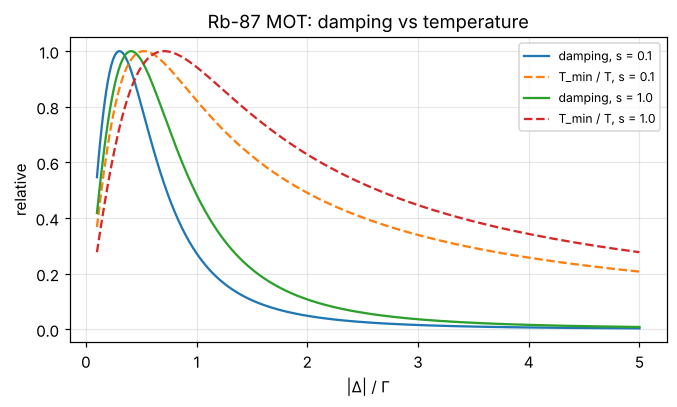

In [3]:
det = np.linspace(0.1, 5, 300)
for s in (0.1, 1.0):
    rs = [mot(det_gamma=d, s=s) for d in det]
    al = np.array([x["alpha"] for x in rs]); T = np.array([x["T_MOT_uK"] for x in rs])
    plt.plot(det, al / al.max(), label=f"damping, s = {s}")
    plt.plot(det, T.min() / T, "--", label=f"T_min / T, s = {s}")
    print(f"s = {s}: damping peaks at |Δ|/Γ = {det[al.argmax()]:.2f}, temperature lowest at |Δ|/Γ = {det[T.argmin()]:.2f}")
plt.xlabel("|Δ| / Γ"); plt.ylabel("relative"); plt.legend(fontsize=8); plt.title("Rb-87 MOT: damping vs temperature")

## 4. Compare species
Same beams and gradient for every species in the table.

In [4]:
print(f"{'species':>7} {'T_D (µK)':>9} {'v_c (m/s)':>10} {'f_MOT (Hz)':>11} {'σ (µm)':>8}")
for sp in ATOMS:
    x = mot(sp)
    print(f"{sp:>7} {x['T_Doppler_uK']:9.0f} {x['v_cap']:10.2f} {x['f_trap_Hz']:11.1f} {x['sigma_um']:8.0f}")

species  T_D (µK)  v_c (m/s)  f_MOT (Hz)   σ (µm)
   Rb87       146       7.10       441.6       58
  Cs133       126       6.69       341.7       56
   Na23       235       8.65       988.2       64
    Li7       141       5.91      1676.0       53
    K39       145       6.94       665.3       57

## 5. Check against the page
Values shown by the page at its default settings (⁸⁷Rb, |Δ| = 1.5 Γ, s = 1, 15 G/cm), read from the live page when this notebook was built.

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

DECIMALS = dict(f_trap_Hz=1, v_cap=2, T_Doppler_uK=0, R_sc_MHz=2, tau_damp_ms=1, sigma_um=0)
page = dict(alpha=0.0678e-20, kappa=0.111e-17, f_trap_Hz=441.6, v_cap=7.10, T_Doppler_uK=146,
            a_max=5.61e4, R_sc_MHz=1.73, tau_damp_ms=0.2, sigma_um=58)
check(r, page)

       alpha: notebook 6.782e-22    page 6.78e-22   OK
       kappa: notebook 1.111e-18    page 1.11e-18   OK
   f_trap_Hz: notebook 441.6        page 441.6      OK
       v_cap: notebook 7.098        page 7.1        OK
T_Doppler_uK: notebook 145.5        page 146        OK
       a_max: notebook 5.606e+04    page 56100      OK
    R_sc_MHz: notebook 1.732        page 1.73       OK
 tau_damp_ms: notebook 0.2128       page 0.2        OK
    sigma_um: notebook 57.58        page 58         OK
All values match the page.